In [1]:
import pandas as pd

In [2]:
# https://www.ssb.no/statbank/table/10487

In [3]:
df = pd.read_csv("statsbudsjett.csv", sep=";").T
df.columns = df.iloc[0]
df = df[1:]

df.index = df.index.str.replace("Bel�p ", "")



In [4]:
df

hovedpost,A. INNTEKTER I ALT,Salg av varer og tjenester,Driftsresultat i statens petroleumsvirksomhet,Avskrivninger og inntekter av statens petroleumsvirksomhet,Avskrivninger og inntekter av statens forretningsdrift ellers,Andre inntekter i samband med bygg og anlegg,Overf�ringer i alt,Skatter og avgifter,Medlemspremier til folketrygden,Arbeidsgiveravgift til folketrygden,...,Overf�ringer til kommuner og fylkeskommuner,"Pensjoner, trygder mv, folketrygden",Renteutgifter vedr. statsgjelden,Andre overf�ringer,C. OVERSKUDD F�R NETTO AVSETNING TIL STATENS PENSJONSFOND - UTLAND,D. NETTO AVSETNING TIL STATENS PENSJONSFOND - UTLAND,E=C-D. OVERSKUDD F�R L�NETRANSAKSJONER,F. NETTO UTL�N MV,G. AVDRAG P� STATSGJELDEN,H=F+G-E. FINANSIERINGSBEHOV
2014,1293028,18481,115500,22800,1802,335,1134110,791705,122300,165500,...,200425,383923,10726,241648,176629,176627,2,62790,0,62788
2015,1331515,18445,121000,26700,2031,291,1163048,792706,131763,171090,...,206767,418331,12872,258663,129731,129730,1,71536,61419,132954
2016,1252490,25826,92200,23700,2229,221,1108314,719618,134634,175697,...,217558,439216,10698,269338,-4907,-4907,0,54430,..,54430
2017,1180570,17757,66400,25400,2422,381,1068210,678160,139524,177134,...,231377,460162,11619,298691,-121236,-121235,-1,-5054,63207,58154
2018,1255664,16778,76900,22200,2388,618,1136780,738192,144613,182205,...,235792,470295,8872,308805,-72316,-72317,1,-62451,0,-62452
2019,1432227,24265,107900,22100,2873,516,1274573,852880,150714,191806,...,243186,478166,10489,331362,53327,53328,-1,639,76515,77155
2020,1446478,25874,87200,22900,2785,667,1307052,865580,156500,202600,...,252251,497650,10016,356551,3868,3867,1,10113,0,10112
2021,1240602,19787,71700,24900,1666,2029,1120520,696683,155130,203390,...,261695,528623,10161,395476,-298099,-298099,0,9793,88000,97793
2022,1558996,20616,95500,24900,1650,1044,1415286,959351,163833,214157,...,260111,553372,10251,398375,-22568,-22565,-3,95596,0,95599
2023,2881424,22851,513300,27000,1663,2573,2314037,1789538,176246,244916,...,290287,588510,11530,479011,1127604,1127604,0,-74081,78457,4376


In [5]:
for col in df.columns:
    df[col] = df[col].replace("..", "0").astype(float)
    df[col] = df[col] / 1e3

In [6]:
df.columns

Index(['A. INNTEKTER I ALT', 'Salg av varer og tjenester',
       'Driftsresultat i statens petroleumsvirksomhet',
       'Avskrivninger og inntekter av statens petroleumsvirksomhet',
       'Avskrivninger og inntekter av statens forretningsdrift ellers',
       'Andre inntekter i samband med bygg og anlegg', 'Overf�ringer i alt',
       '  Skatter og avgifter', '  Medlemspremier til folketrygden',
       '  Arbeidsgiveravgift til folketrygden', '  Renter og utbytte',
       '  Overf�ringer fra andre statlige regnskaper',
       '  Overf�ringer fra kommuner og fylkeskommuner',
       '  Overf�ringer fra Norges bank', '  Andre overf�ringer',
       'B. UTGIFTER I ALT', 'Statens egne driftsutgifter i alt',
       '  L�nn og godtgj�relser', '  Varer og tjenester',
       '  Andre driftsutgifter', '  Driftsresultat i statens forretningsdrift',
       'Nybygg, anlegg mv i alt', '  Nybygg mv statens petroleumsvirksomhet',
       '  Nybygg mv statens forretningsdrift ellers',
       '  Nybygg

<Axes: title={'center': 'B. UTGIFTER I ALT'}, xlabel='År', ylabel='Beløp i milliarder'>

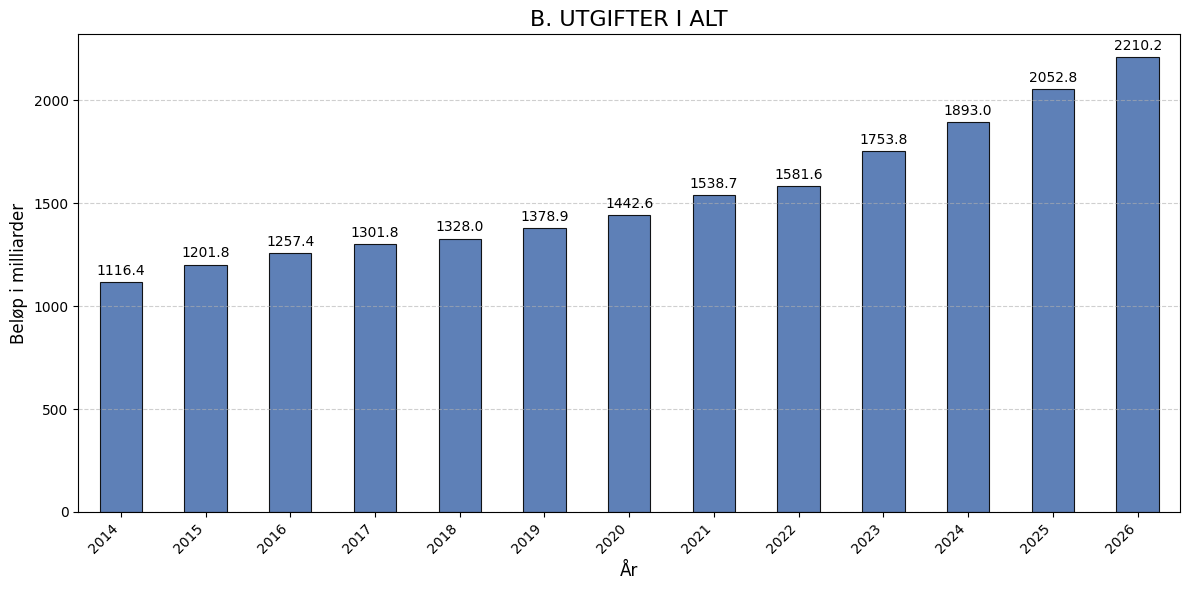

In [7]:
import matplotlib.pyplot as plt

def plot_budget_column(values_to_plot, column_name):

    ax = values_to_plot.plot(
        kind="bar",
        figsize=(12, 6),
        color="#4c72b0",
        edgecolor="black",
        linewidth=0.8,
        alpha=0.9
    )
    
    ax.set_title(column_name, fontsize=16)
    ax.set_xlabel("År", fontsize=12)
    ax.set_ylabel("Beløp i milliarder", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.set_xticklabels(df.index, rotation=45, ha="right")
    
    # Add numbers on top of each bar
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)
    
    plt.tight_layout()
    return ax

plot_budget_column(df["B. UTGIFTER I ALT"], "B. UTGIFTER I ALT")

<Axes: title={'center': 'A. INNTEKTER I ALTT'}, xlabel='År', ylabel='Beløp i milliarder'>

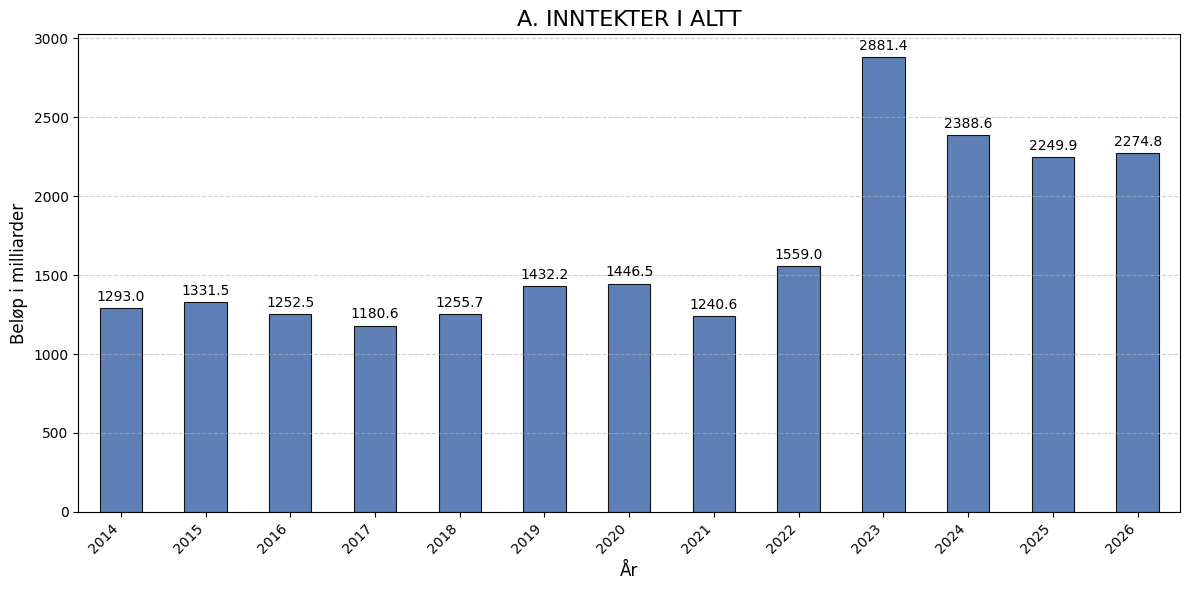

In [8]:
plot_budget_column(df["A. INNTEKTER I ALT"], "A. INNTEKTER I ALTT")

<Axes: title={'center': 'Overskudd'}, xlabel='År', ylabel='Beløp i milliarder'>

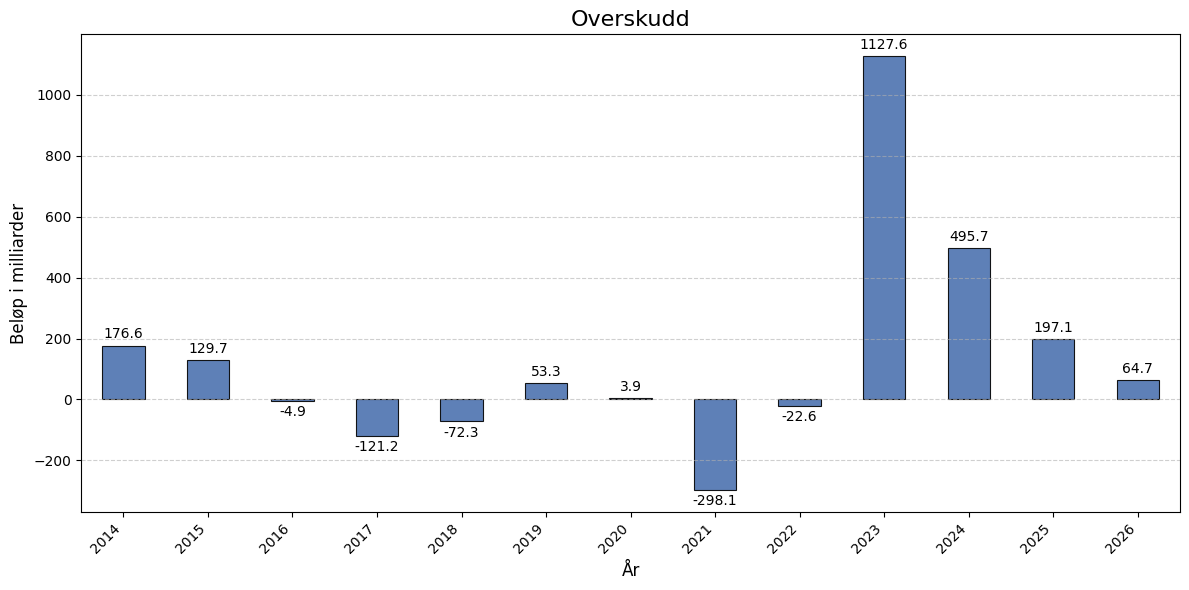

In [9]:
plot_budget_column(df["C. OVERSKUDD F�R NETTO AVSETNING TIL STATENS PENSJONSFOND - UTLAND"], "Overskudd")

<Axes: title={'center': 'Skatter og avgifter'}, xlabel='År', ylabel='Beløp i milliarder'>

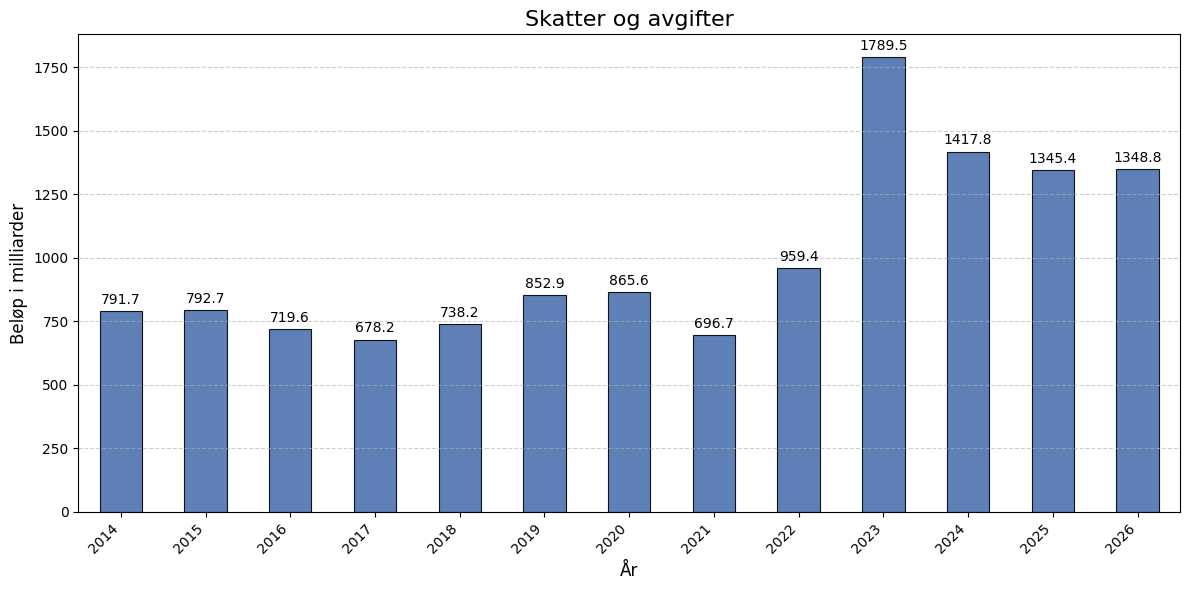

In [10]:
plot_budget_column(df["  Skatter og avgifter"], "Skatter og avgifter")

<Axes: title={'center': 'Statens egne driftsutgifter i alt'}, xlabel='År', ylabel='Beløp i milliarder'>

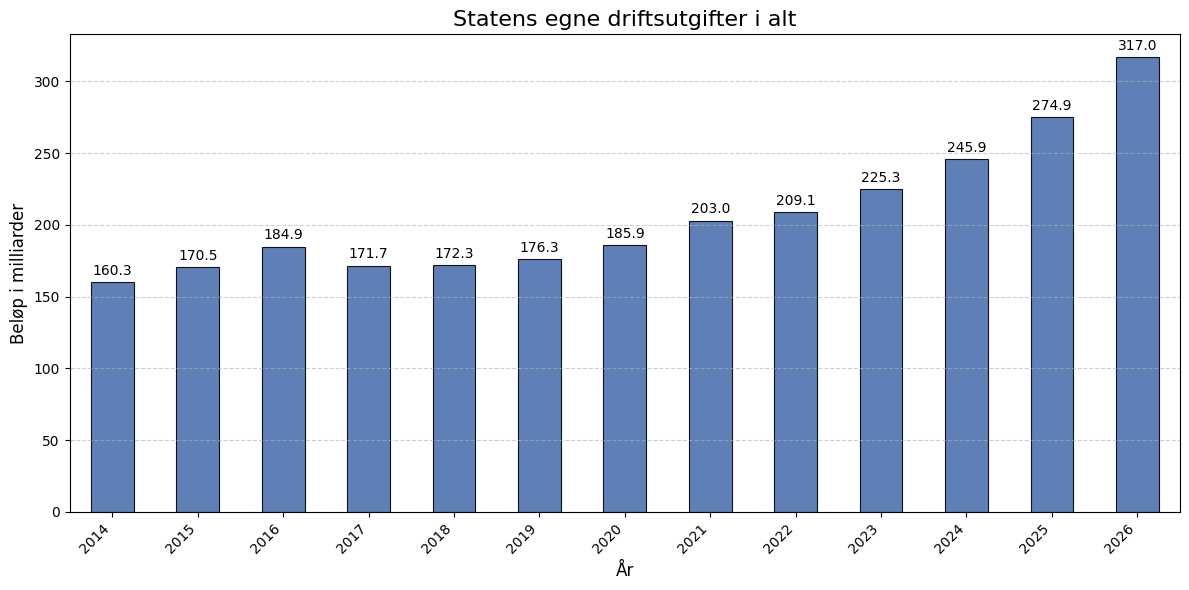

In [11]:
plot_budget_column(df["Statens egne driftsutgifter i alt"], "Statens egne driftsutgifter i alt")

<Axes: title={'center': '  Pensjoner, trygder mv, folketrygden'}, xlabel='År', ylabel='Beløp i milliarder'>

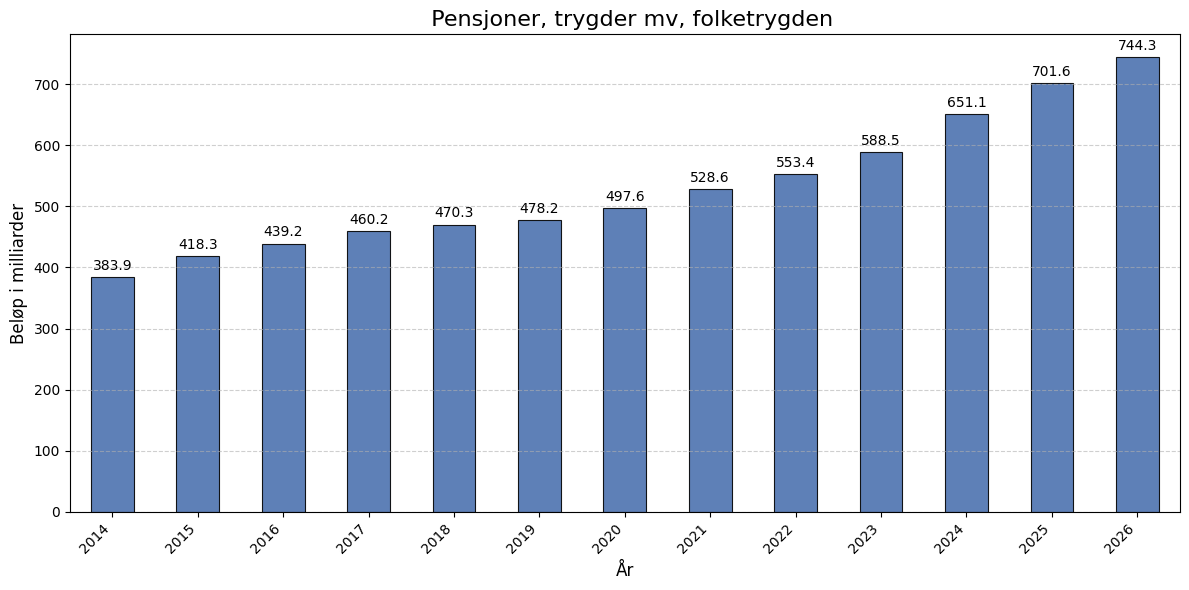

In [12]:
kolonne = 15 + 13



plot_budget_column(df.iloc[:,kolonne], df.columns[kolonne])


<Axes: title={'center': '  Skatter og avgifter'}, xlabel='År', ylabel='Beløp i milliarder'>

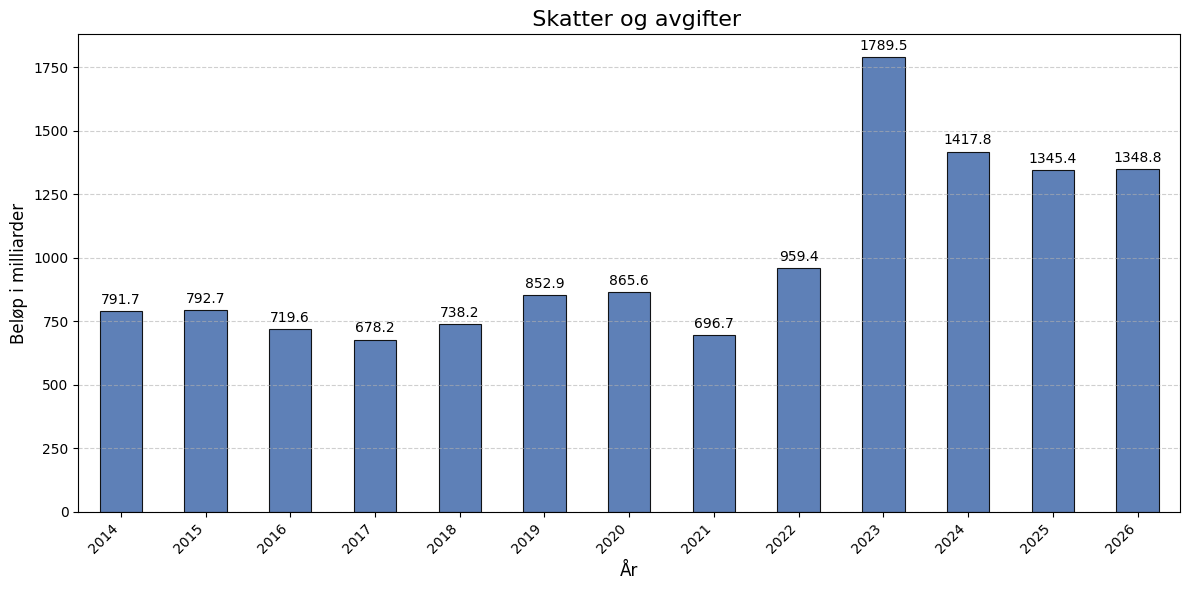

In [13]:
kolonne = 7

plot_budget_column(df.iloc[:,kolonne], df.columns[kolonne])


In [25]:
df = pd.read_csv("statsbudsjett_2026_oversikt.csv", sep=";")

In [26]:
df


,Kategori,Beløp (Milliarder NOK)
0,Statsbudsjettets inntekter (utenom petroleum),1712.2
1,Sum skatter og avgifter fra Fastlands-Norge,1560.2
2,- Skatt på formue og inntekt,514.8
3,- Arbeidsgiveravgift og trygdeavgift,514.2
4,- Merverdiavgift,421.0
5,- Avgifter på tobakk og alkohol,24.0
6,- Avgifter på motorvogner,18.7
7,- Elektrisitetsavgift,4.8
8,- Tollinntekter,3.6
9,- Andre avgifter,59.3


In [41]:
inntekter = df.iloc[2:13]
inntekter = inntekter.T
inntekter.columns = inntekter.iloc[0]
inntekter = inntekter[1:]
 

utgifter = df.iloc[15:34]
utgifter = utgifter.T
utgifter.columns = utgifter.iloc[0]
utgifter = utgifter[1:].reset_index(drop=True)


In [42]:
inntekter


Kategori,- Skatt på formue og inntekt,- Arbeidsgiveravgift og trygdeavgift,- Merverdiavgift,- Avgifter på tobakk og alkohol,- Avgifter på motorvogner,- Elektrisitetsavgift,- Tollinntekter,- Andre avgifter,Renter og aksjeutbytte mv.,Inntekter fra statens forvaltningsbedrifter,Andre inntekter
Beløp (Milliarder NOK),514.8,514.2,421.0,24.0,18.7,4.8,3.6,59.3,83.9,5.2,62.9


<Axes: title={'center': 'Inntekter og utgifter side by side'}, xlabel='Type', ylabel='Milliarder NOK'>

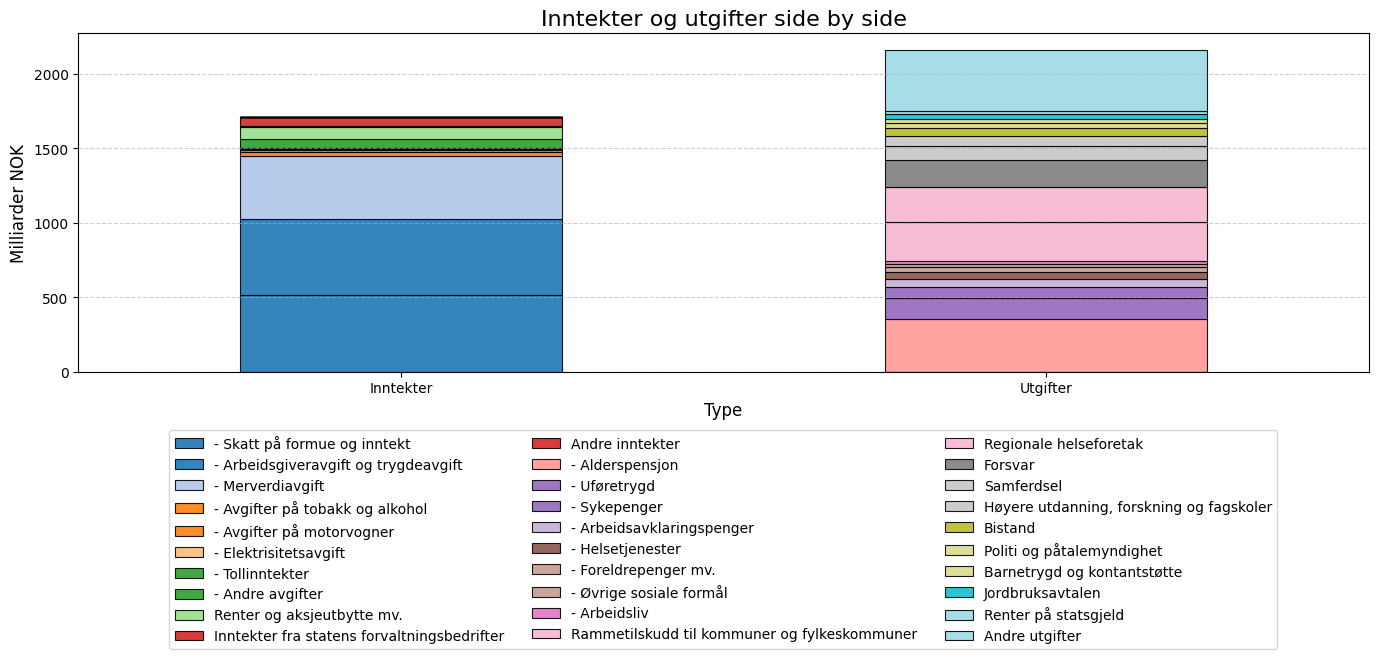

In [45]:
combined = pd.concat([inntekter, utgifter], axis=0, sort=False).fillna(0)
combined.index = ["Inntekter", "Utgifter"]

ax = combined.plot(
    kind="bar",
    figsize=(14, 7),
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9,
    colormap="tab20",
    stacked=True
)

ax.set_title("Inntekter og utgifter side by side", fontsize=16)
ax.set_xlabel("Type", fontsize=12)
ax.set_ylabel("Milliarder NOK", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_xticklabels(combined.index, rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
ax


In [49]:
df


,Kategori,Beløp (Milliarder NOK)
0,Statsbudsjettets inntekter (utenom petroleum),1712.2
1,Sum skatter og avgifter fra Fastlands-Norge,1560.2
2,- Skatt på formue og inntekt,514.8
3,- Arbeidsgiveravgift og trygdeavgift,514.2
4,- Merverdiavgift,421.0
5,- Avgifter på tobakk og alkohol,24.0
6,- Avgifter på motorvogner,18.7
7,- Elektrisitetsavgift,4.8
8,- Tollinntekter,3.6
9,- Andre avgifter,59.3


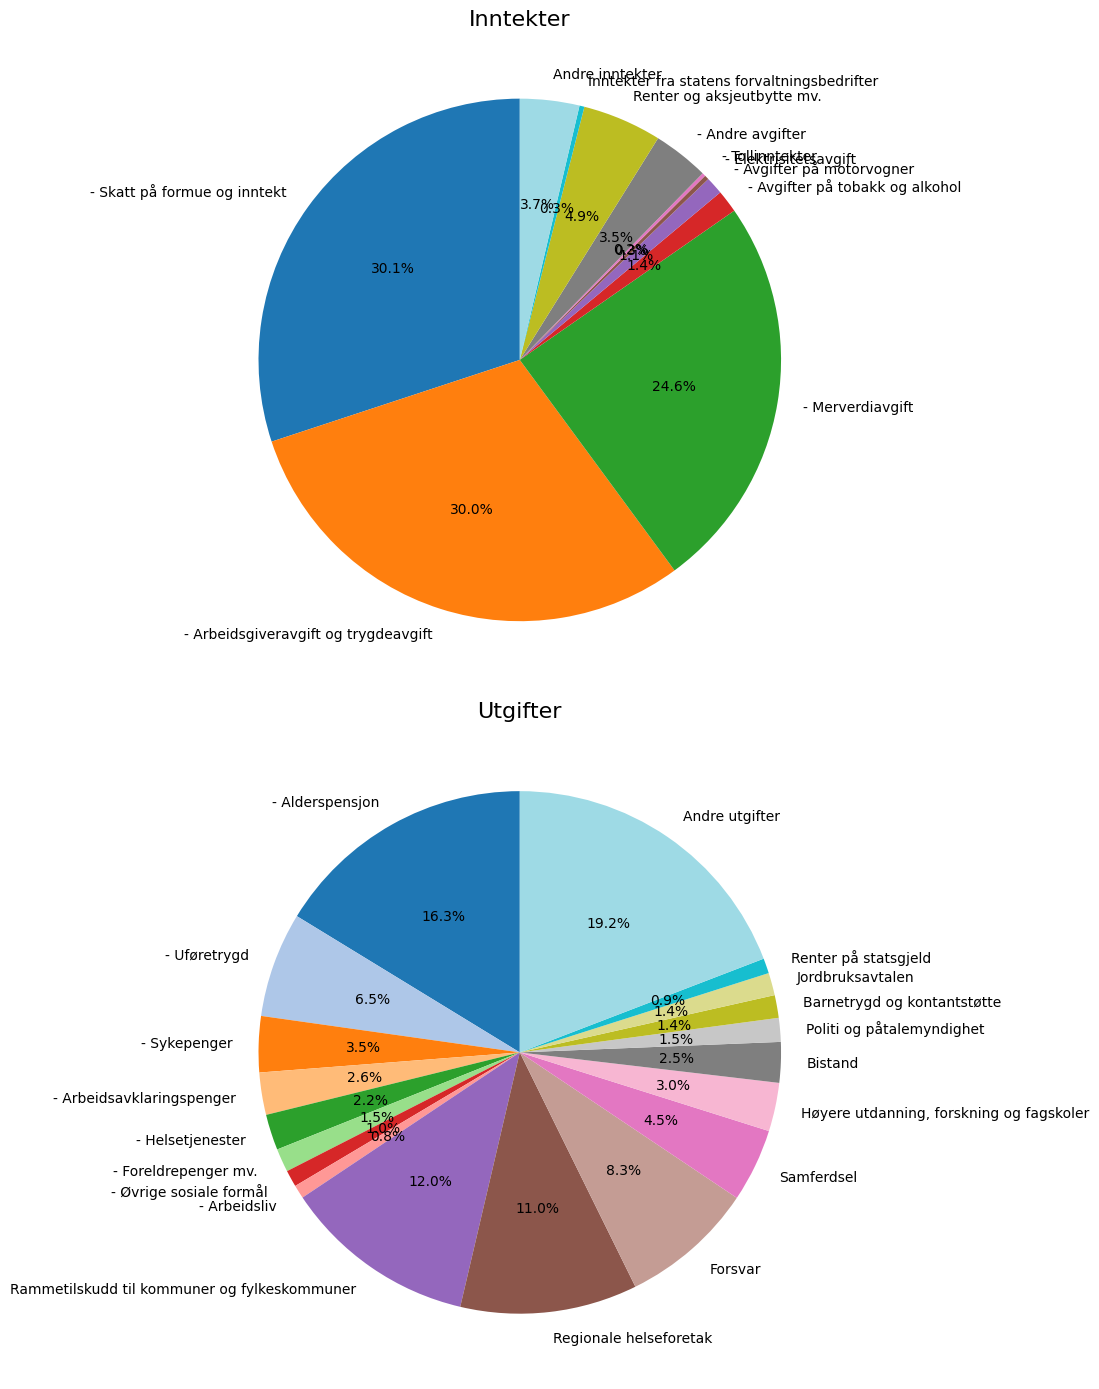

In [48]:
import matplotlib.pyplot as plt

# Pie chart for Inntekter
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(28, 14))


inntekter.iloc[0].plot.pie(ax=ax1, autopct='%1.1f%%', startangle=90, colormap='tab20')
ax1.set_title("Inntekter", fontsize=16)
ax1.set_ylabel('')

# Pie chart for Utgifter
utgifter.iloc[0].plot.pie(ax=ax2, autopct='%1.1f%%', startangle=90, colormap='tab20')
ax2.set_title("Utgifter", fontsize=16)
ax2.set_ylabel('')

plt.tight_layout()
plt.show()


In [ ]:
plt.subplots()

<Axes: xlabel='Kategori'>

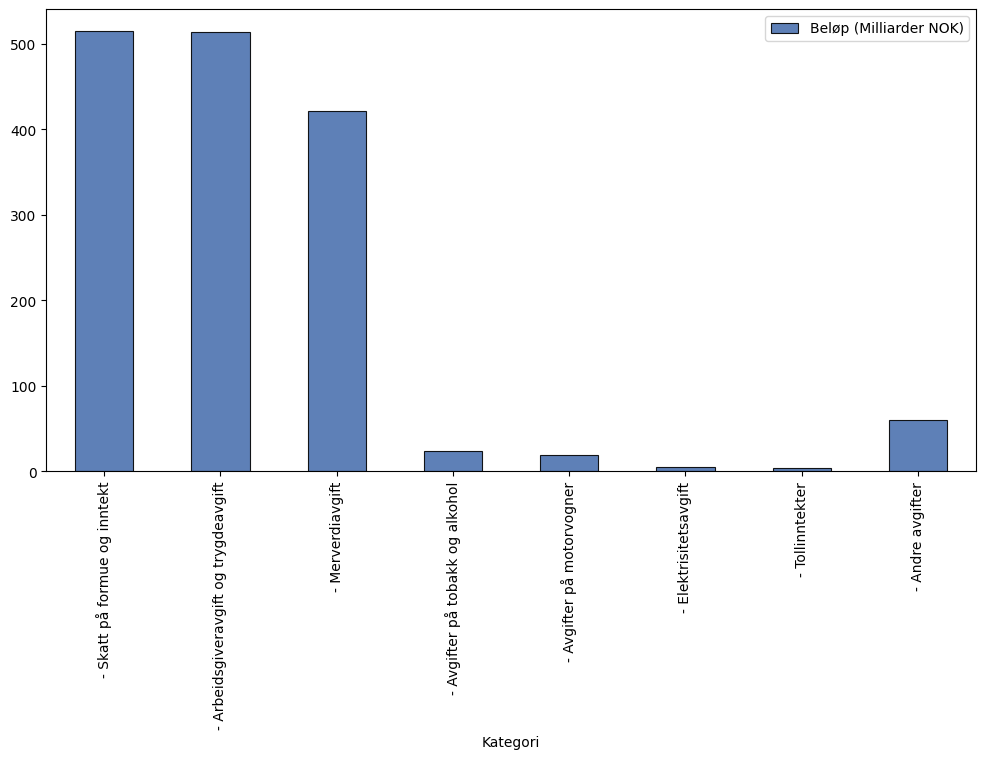

In [17]:
inntekter.plot(kind="bar", x=df.columns[0], y=df.columns[1], figsize=(12, 6), color="#4c72b0", edgecolor="black", linewidth=0.8, alpha=0.9, stacked=True)


<Axes: title={'center': 'A. INNTEKTER I ALT'}, xlabel='År', ylabel='Beløp i milliarder'>

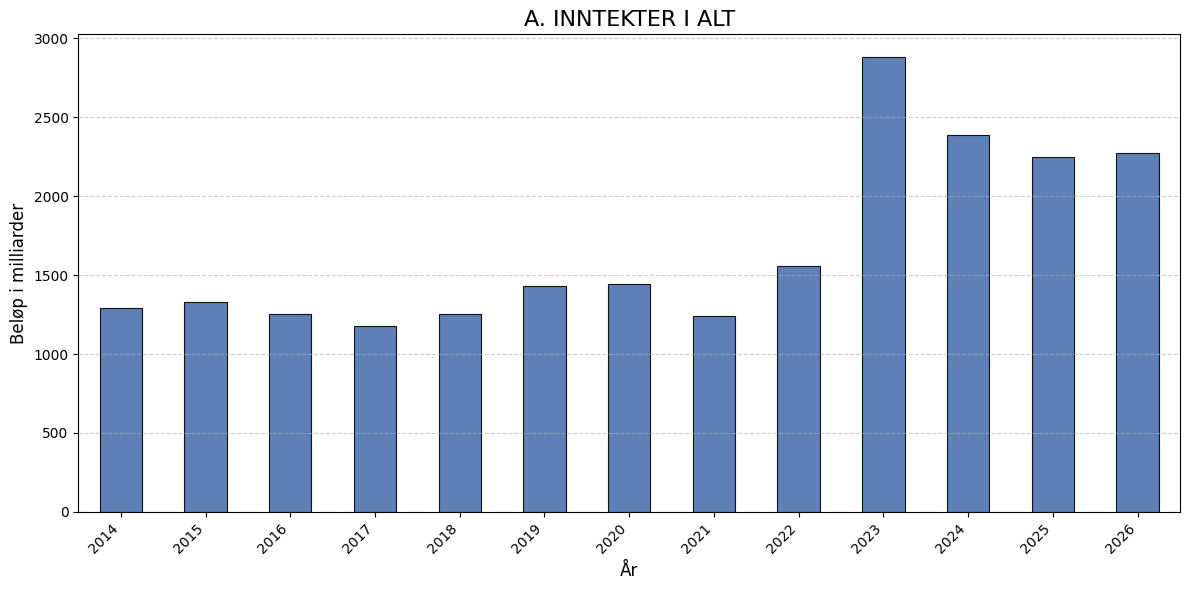

In [70]:
def plot_budget_column(values_to_plot, column_name):

    ax = values_to_plot.plot(
        kind="bar",
        figsize=(12, 6),
        color="#4c72b0",
        edgecolor="black",
        linewidth=0.8,
        alpha=0.9
    )
    
    ax.set_title(column_name, fontsize=16)
    ax.set_xlabel("År", fontsize=12)
    ax.set_ylabel("Beløp i milliarder", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.set_xticklabels(df.index, rotation=45, ha="right")
    
    plt.tight_layout()
    return ax

plot_budget_column(df['A. INNTEKTER I ALT'], "A. INNTEKTER I ALT")

<Axes: title={'center': 'Statens egne driftsutgifter i alt'}, xlabel='År', ylabel='Beløp i milliarder'>

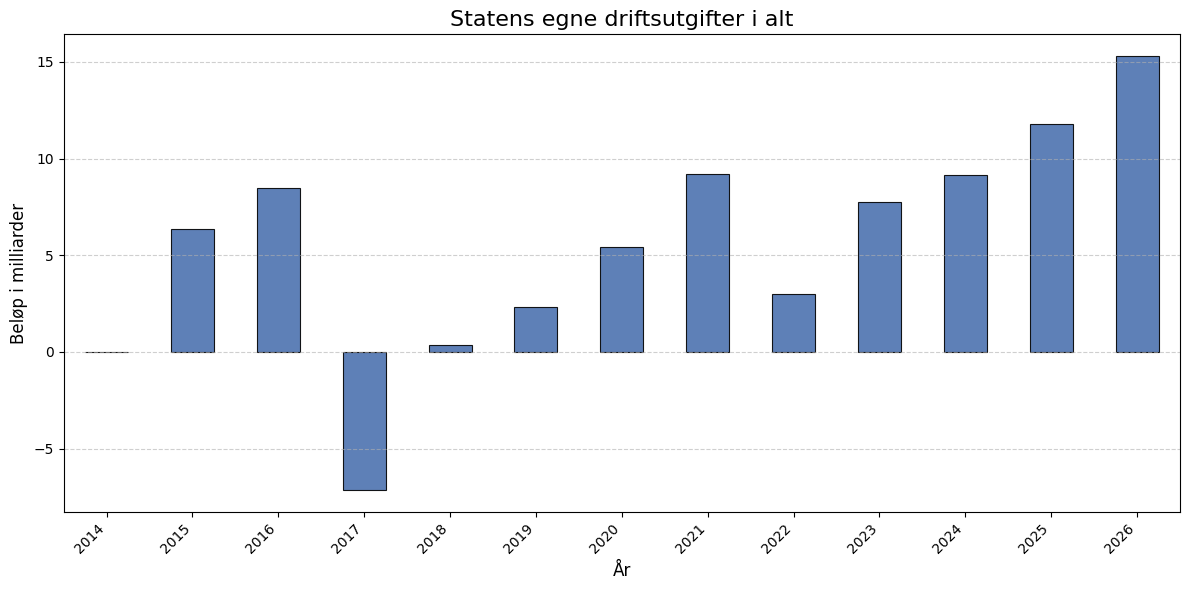

In [55]:
plot_budget_column((df["Statens egne driftsutgifter i alt"].pct_change() * 100),"Statens egne driftsutgifter i alt")

In [60]:
df.columns = df.columns.str.replace(" ", "_").str.lower().str.replace(".", "")

In [62]:
df.columns

Index(['a_inntekter_i_alt', 'salg_av_varer_og_tjenester',
       'driftsresultat_i_statens_petroleumsvirksomhet',
       'avskrivninger_og_inntekter_av_statens_petroleumsvirksomhet',
       'avskrivninger_og_inntekter_av_statens_forretningsdrift_ellers',
       'andre_inntekter_i_samband_med_bygg_og_anlegg', 'overf�ringer_i_alt',
       '__skatter_og_avgifter', '__medlemspremier_til_folketrygden',
       '__arbeidsgiveravgift_til_folketrygden', '__renter_og_utbytte',
       '__overf�ringer_fra_andre_statlige_regnskaper',
       '__overf�ringer_fra_kommuner_og_fylkeskommuner',
       '__overf�ringer_fra_norges_bank', '__andre_overf�ringer',
       'b_utgifter_i_alt', 'statens_egne_driftsutgifter_i_alt',
       '__l�nn_og_godtgj�relser', '__varer_og_tjenester',
       '__andre_driftsutgifter', '__driftsresultat_i_statens_forretningsdrift',
       'nybygg,_anlegg_mv_i_alt', '__nybygg_mv_statens_petroleumsvirksomhet',
       '__nybygg_mv_statens_forretningsdrift_ellers',
       '__nybygg,_